# HW3 - Neural Network Model of BTS Data

## Predicting Airline Arrival Delays

The goal of this analysis is to predict whether a flight will arrive more than 15 minutes late using the BTS Airline On-Time Performance dataset. This is formulated as a binary classification problem, where a delayed flight is assigned a value of 1 and a non-delayed flight is assigned a value of 0.

A PyTorch neural network will be trained and compared with a logistic regression model. Model performance will be evaluated on held-out test data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [2]:
np.random.seed(42)
torch.manual_seed(42)

In [3]:
df = pd.read_csv("T_ONTIME_REPORTING.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (544003, 7)


,CRS_DEP_TIME,DEP_DELAY,TAXI_OUT,ARR_DELAY,CANCELLED,CRS_ELAPSED_TIME,DISTANCE
0,2,-10.0,13.0,-38.0,0.0,103.0,413.0
1,2,-8.0,20.0,-28.0,0.0,92.0,264.0
2,2,-2.0,21.0,-23.0,0.0,135.0,552.0
3,2,-1.0,13.0,-21.0,0.0,88.0,296.0
4,2,1.0,16.0,-18.0,0.0,135.0,585.0


In [4]:
print(df.columns.tolist())

['CRS_DEP_TIME', 'DEP_DELAY', 'TAXI_OUT', 'ARR_DELAY', 'CANCELLED', 'CRS_ELAPSED_TIME', 'DISTANCE']


In [5]:
# Keep only non-cancelled flights
df_model = df[df["CANCELLED"] == 0].copy()

# Create binary response:
# 1 = arrival delay greater than 15 minutes
# 0 = arrival delay of 15 minutes or less
df_model["ARR_DELAYED"] = (df_model["ARR_DELAY"] > 15).astype(int)

features = [
    "CRS_DEP_TIME",
    "DEP_DELAY",
    "TAXI_OUT",
    "CRS_ELAPSED_TIME",
    "DISTANCE"
]

# Keep only the variables needed for modeling and remove missing values
df_model = df_model[features + ["ARR_DELAYED"]].dropna()

print("Modeling dataset shape:", df_model.shape)
df_model.head()

Modeling dataset shape: (518368, 6)


,CRS_DEP_TIME,DEP_DELAY,TAXI_OUT,CRS_ELAPSED_TIME,DISTANCE,ARR_DELAYED
0,2,-10.0,13.0,103.0,413.0,0
1,2,-8.0,20.0,92.0,264.0,0
2,2,-2.0,21.0,135.0,552.0,0
3,2,-1.0,13.0,88.0,296.0,0
4,2,1.0,16.0,135.0,585.0,0


In [6]:
print(df_model["ARR_DELAYED"].value_counts())
print()
print(df_model["ARR_DELAYED"].value_counts(normalize=True))

ARR_DELAYED
0    414275
1    104093
Name: count, dtype: int64

ARR_DELAYED
0    0.799191
1    0.200809
Name: proportion, dtype: float64


In [7]:
X = df_model[features].values
y = df_model["ARR_DELAYED"].values

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

Training samples: 414694
Test samples: 103674


In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [9]:
print("Training set shape:", X_train_scaled.shape)
print("Test set shape:", X_test_scaled.shape)

print("\nTraining feature means:")
print(X_train_scaled.mean(axis=0))

print("\nTraining feature standard deviations:")
print(X_train_scaled.std(axis=0))

Training set shape: (414694, 5)
Test set shape: (103674, 5)

Training feature means:
[-1.23917353e-17 -6.39492360e-16 -2.48249407e-16 -5.05527905e-16
 -2.15431896e-16]

Training feature standard deviations:
[1. 1. 1. 1. 1.]


## Logistic Regression

A logistic regression model is used as a baseline classification model. The model is trained using the same standardized training data that will be used for the neural network.

In [10]:
log_model = LogisticRegression(max_iter=1000)

log_model.fit(X_train_scaled, y_train)

log_pred = log_model.predict(X_test_scaled)

In [11]:
log_accuracy = accuracy_score(y_test, log_pred)
log_cm = confusion_matrix(y_test, log_pred)

print(f"Logistic Regression Test Accuracy: {log_accuracy:.4f}")
print("\nConfusion Matrix:")
print(log_cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    log_pred,
    target_names=["Not Delayed", "Delayed"]
))

Logistic Regression Test Accuracy: 0.9454

Confusion Matrix:
[[81365  1490]
 [ 4167 16652]]

Classification Report:
              precision    recall  f1-score   support

 Not Delayed       0.95      0.98      0.97     82855
     Delayed       0.92      0.80      0.85     20819

    accuracy                           0.95    103674
   macro avg       0.93      0.89      0.91    103674
weighted avg       0.94      0.95      0.94    103674



## Neural Network

A feedforward neural network is trained using PyTorch. The network uses the five standardized predictor variables as inputs, two hidden layers with ReLU activation functions, and a single output for binary classification.

In [12]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train, dtype=torch.float32).reshape(-1, 1)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

print("X training tensor:", X_train_tensor.shape)
print("y training tensor:", y_train_tensor.shape)

X training tensor: torch.Size([414694, 5])
y training tensor: torch.Size([414694, 1])


In [13]:
class FlightDelayNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(5, 16)
        self.fc2 = nn.Linear(16, 8)
        self.fc3 = nn.Linear(8, 1)

    def forward(self, x):
        x = torch.relu(self.fc1(x))
        x = torch.relu(self.fc2(x))
        x = self.fc3(x)
        return x


torch.manual_seed(42)

model = FlightDelayNN()
print(model)

FlightDelayNN(
  (fc1): Linear(in_features=5, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=8, bias=True)
  (fc3): Linear(in_features=8, out_features=1, bias=True)
)


In [14]:
criterion_nn = nn.BCEWithLogitsLoss()
optimizer_nn = torch.optim.Adam(model.parameters(), lr=0.001)

In [15]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True
)

In [16]:
num_epochs = 20
train_losses = []

for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0

    for X_batch, y_batch in train_loader:
        optimizer_nn.zero_grad()

        outputs = model(X_batch)
        loss = criterion_nn(outputs, y_batch)

        loss.backward()
        optimizer_nn.step()

        running_loss += loss.item() * X_batch.size(0)

    epoch_loss = running_loss / len(train_dataset)
    train_losses.append(epoch_loss)

    print(f"Epoch {epoch + 1:2d}/{num_epochs}, Loss: {epoch_loss:.4f}")

Epoch  1/20, Loss: 0.2167
Epoch  2/20, Loss: 0.1567
Epoch  3/20, Loss: 0.1547
Epoch  4/20, Loss: 0.1529
Epoch  5/20, Loss: 0.1518
Epoch  6/20, Loss: 0.1512
Epoch  7/20, Loss: 0.1508
Epoch  8/20, Loss: 0.1505
Epoch  9/20, Loss: 0.1503
Epoch 10/20, Loss: 0.1501
Epoch 11/20, Loss: 0.1500
Epoch 12/20, Loss: 0.1499
Epoch 13/20, Loss: 0.1499
Epoch 14/20, Loss: 0.1497
Epoch 15/20, Loss: 0.1497
Epoch 16/20, Loss: 0.1496
Epoch 17/20, Loss: 0.1495
Epoch 18/20, Loss: 0.1495
Epoch 19/20, Loss: 0.1494
Epoch 20/20, Loss: 0.1494


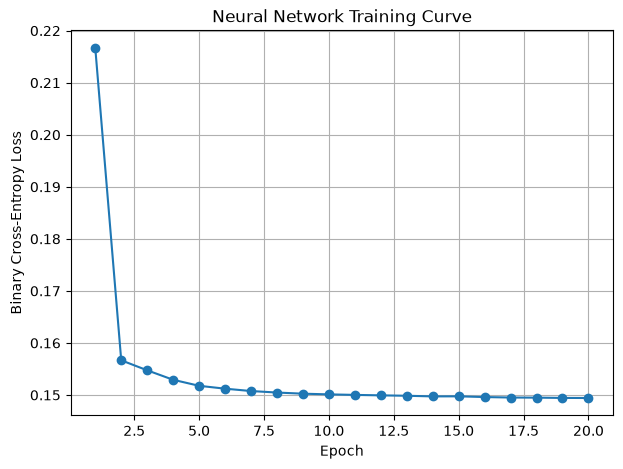

In [17]:
plt.figure(figsize=(7, 5))
plt.plot(range(1, num_epochs + 1), train_losses, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Neural Network Training Curve")
plt.grid(True)
plt.show()

In [18]:
model.eval()

with torch.no_grad():
    test_logits = model(X_test_tensor)
    test_probabilities = torch.sigmoid(test_logits)
    nn_pred = (test_probabilities >= 0.5).int().numpy().flatten()

In [19]:
nn_accuracy = accuracy_score(y_test, nn_pred)
nn_cm = confusion_matrix(y_test, nn_pred)

print(f"Neural Network Test Accuracy: {nn_accuracy:.4f}")
print("\nConfusion Matrix:")
print(nn_cm)

print("\nClassification Report:")
print(classification_report(
    y_test,
    nn_pred,
    target_names=["Not Delayed", "Delayed"]
))

Neural Network Test Accuracy: 0.9477

Confusion Matrix:
[[81421  1434]
 [ 3983 16836]]

Classification Report:
              precision    recall  f1-score   support

 Not Delayed       0.95      0.98      0.97     82855
     Delayed       0.92      0.81      0.86     20819

    accuracy                           0.95    103674
   macro avg       0.94      0.90      0.91    103674
weighted avg       0.95      0.95      0.95    103674



## Model Comparison and Test Error

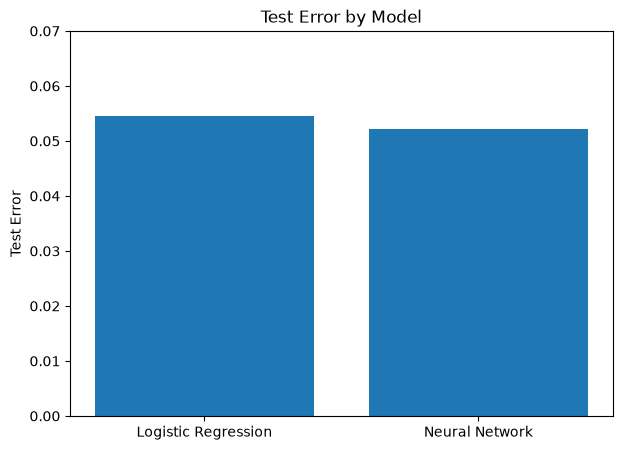

Logistic Regression Test Error: 0.0546
Neural Network Test Error: 0.0523


In [20]:
model_names = ["Logistic Regression", "Neural Network"]

test_errors = [
    1 - log_accuracy,
    1 - nn_accuracy
]

plt.figure(figsize=(7, 5))
plt.bar(model_names, test_errors)
plt.ylabel("Test Error")
plt.title("Test Error by Model")
plt.ylim(0, 0.07)
plt.show()

for name, error in zip(model_names, test_errors):
    print(f"{name} Test Error: {error:.4f}")

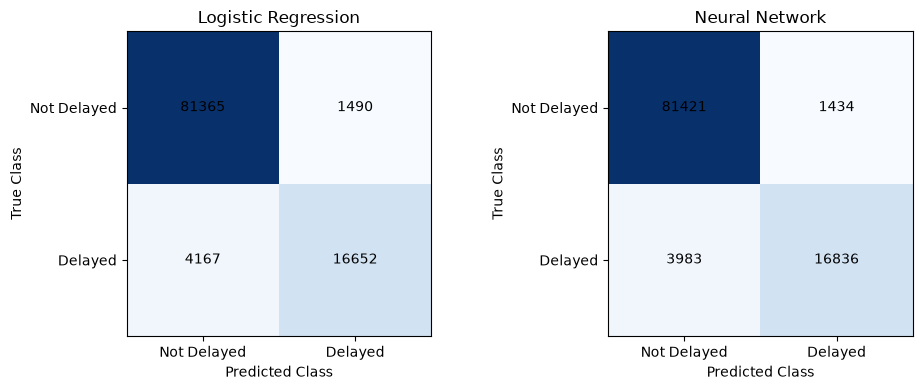

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].imshow(log_cm, cmap="Blues")
axes[0].set_title("Logistic Regression")
axes[0].set_xlabel("Predicted Class")
axes[0].set_ylabel("True Class")

axes[1].imshow(nn_cm, cmap="Blues")
axes[1].set_title("Neural Network")
axes[1].set_xlabel("Predicted Class")
axes[1].set_ylabel("True Class")

for ax, cm in zip(axes, [log_cm, nn_cm]):
    ax.set_xticks([0, 1], ["Not Delayed", "Delayed"])
    ax.set_yticks([0, 1], ["Not Delayed", "Delayed"])
    
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.show()

## Results and Discussion

The logistic regression model achieved a test accuracy of 94.54%, corresponding to a test error of 5.46%. The neural network achieved a slightly higher test accuracy of 94.77%, corresponding to a test error of 5.23%. Thus, the neural network provided a small improvement over logistic regression on the held-out test data.

The neural network training loss decreased from 0.2167 during the first epoch to 0.1494 after 20 epochs. Most of the reduction occurred during the first few epochs, followed by smaller improvements as training continued. This indicates that the optimization converged to a relatively stable solution.

The dataset is imbalanced, with approximately 79.9% of flights classified as not delayed and 20.1% classified as delayed. Therefore, accuracy alone does not completely describe model performance. For delayed flights, logistic regression achieved a recall of 0.80 and an F1-score of 0.85, while the neural network achieved a recall of 0.81 and an F1-score of 0.86. The neural network therefore showed a small improvement in identifying delayed flights as well as in overall test accuracy.

Both models performed well, suggesting that the selected variables contain substantial information about arrival delays. In particular, departure delay and taxi-out time provide information about the flight after the departure process has begun. The relatively small improvement from the neural network suggests that much of the relationship between these predictors and the probability of an arrival delay can already be captured by logistic regression, although the neural network can model additional nonlinear relationships.

Also, I used the same data as the previous 2 homeworks. Saves a bit of time.